# 03 · The extended Kalman filter

We drop the compass. The state is the full pose $x = (p^x, p^y, \theta)$. The motion model
$f$ and the range–bearing model $h$ are non-linear, so a Gaussian belief does not stay
Gaussian. The **EKF** keeps it Gaussian anyway: it replaces $f$ and $h$ by their first-order
Taylor expansions around the current estimate and then applies the Kalman filter equations.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import (World, simulate, EKF, run_filter, motion_model, motion_jacobians,
                            range_bearing, range_bearing_jacobian, position_error, nees, nees_bounds,
                            wrap_angle)
from bayesian_filters import viz
viz.style()

## 1. Linearisation

**Motion.** With $\theta' = \theta + \delta$,
$$
f(x,u) = \begin{pmatrix} p^x + s\cos\theta' \\ p^y + s\sin\theta' \\ \theta'\end{pmatrix},\qquad
F = \frac{\partial f}{\partial x} = \begin{pmatrix}1&0&-s\sin\theta'\\0&1&s\cos\theta'\\0&0&1\end{pmatrix},\qquad
V = \frac{\partial f}{\partial u} = \begin{pmatrix}\cos\theta'&-s\sin\theta'\\ \sin\theta'&s\cos\theta'\\0&1\end{pmatrix}.
$$
The noise is in the control, $u + \varepsilon$ with $\varepsilon\sim\mathcal N(0,M)$, so to first
order the process noise in state space is $Q_t = V M V^\top$.

**Measurement.** For a landmark at $\ell$, let $d = \ell - p$ and $q = \lVert d\rVert^2$. Then
$$
h(x) = \begin{pmatrix}\sqrt q\\ \operatorname{atan2}(d_y, d_x) - \theta\end{pmatrix},\qquad
H = \frac{\partial h}{\partial x} = \begin{pmatrix} -d_x/\sqrt q & -d_y/\sqrt q & 0\\ d_y/q & -d_x/q & -1\end{pmatrix}.
$$
With several visible landmarks the rows are stacked and $R$ is block diagonal.

Hand-derived Jacobians are a classic source of bugs, so we check them against finite differences:

In [2]:
def numeric_jacobian(fun, x, eps=1e-6):
    cols = []
    for i in range(len(x)):
        dx = np.zeros(len(x)); dx[i] = eps
        cols.append((fun(x + dx) - fun(x - dx)) / (2 * eps))
    return np.array(cols).T

world = World.default()
x, u = np.array([12.0, -30.0, 2.5]), np.array([4.0, 0.06])
F, V = motion_jacobians(x, u)
H = range_bearing_jacobian(x, world.landmarks)
print("max |F - numeric| =", np.abs(F - numeric_jacobian(lambda s: motion_model(s, u), x)).max())
print("max |V - numeric| =", np.abs(V - numeric_jacobian(lambda v: motion_model(x, v), u)).max())
print("max |H - numeric| =", np.abs(H - numeric_jacobian(lambda s: range_bearing(s, world.landmarks).ravel(), x)).max())

max |F - numeric| = 1.0279563866788521e-09
max |V - numeric| = 1.157482221181283e-09
max |H - numeric| = 2.4653648567074526e-09


## 2. The filter

$$
\begin{aligned}
&\textbf{predict:}\quad \bar x = f(\hat x, u),\qquad \bar P = F P F^\top + V M V^\top\\
&\textbf{update:}\quad y = z - h(\bar x)\ \ (\text{bearing components wrapped}),\quad S = H\bar P H^\top + R,\\
&\phantom{\textbf{update:}}\quad K = \bar P H^\top S^{-1},\quad \hat x = \bar x + K y\ \ (\theta\ \text{wrapped}),\quad P = (I-KH)\bar P(I-KH)^\top + KRK^\top .
\end{aligned}
$$

Compared to the KF of notebook 02, the only changes are that the *mean* goes through the true
non-linear functions, while the *covariance* goes through their Jacobians, evaluated at the
current estimate.

**Angles.** Forgetting to wrap the bearing innovation is the most common EKF bug in
localisation. If the predicted bearing is $3.10$ and the measured one $-3.12$, the raw
difference is $-6.22$ rad instead of $+0.06$, and the update throws the mower across the lawn.

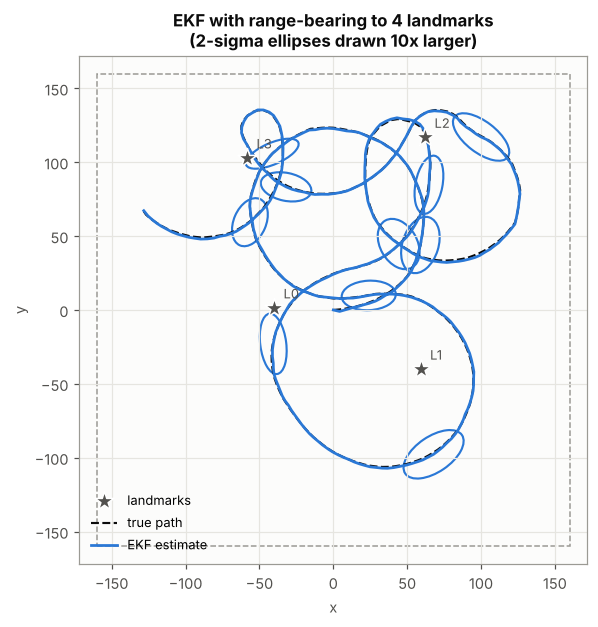

In [3]:
run = simulate(world, n_steps=400, seed=1)
P0 = np.diag([10.0, 10.0, 0.05])
ekf = EKF.from_world(world, run.truth[0], P0)
res = run_filter(ekf, run)

fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_world(ax, world)
viz.plot_path(ax, run.truth, "truth", label="true path")
viz.plot_path(ax, res.means, "EKF", label="EKF estimate")
for t in range(20, run.n_steps + 1, 40):
    viz.cov_ellipse(ax, res.means[t], 100 * res.covs[t], n_sigma=2, name="EKF")
ax.set_title("EKF with range-bearing to 4 landmarks\n(2-sigma ellipses drawn 10x larger)")
ax.legend(loc="lower left", fontsize=8.5)
plt.show()

Each error component should stay inside the filter's own $\pm 2\sigma$ band about 95% of the
time:

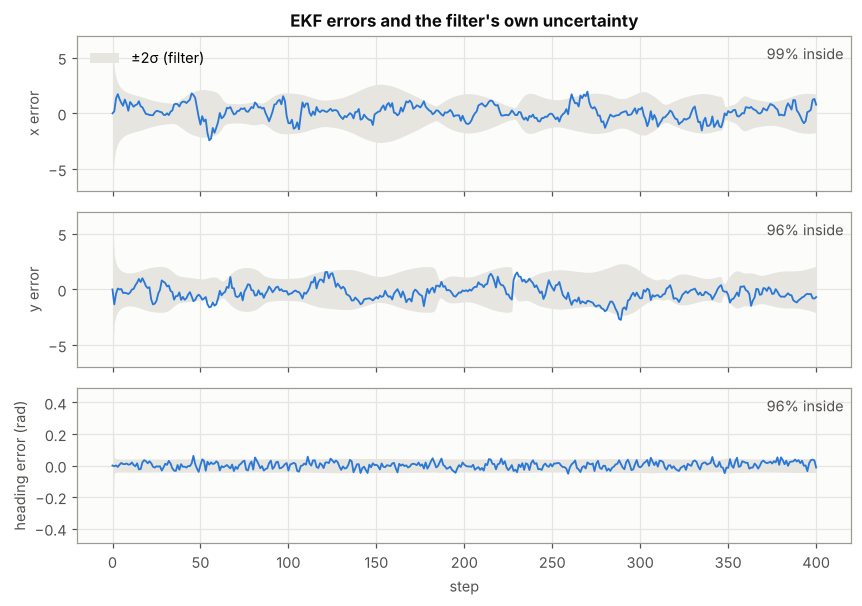

position RMSE 1.01   (range noise 5, bearing noise 0.05 rad, ~5 units at 100 units distance)


In [4]:
err = res.means - run.truth
err[:, 2] = wrap_angle(err[:, 2])
sd = np.sqrt(np.einsum("tii->ti", res.covs))
fig, axes = plt.subplots(3, 1, figsize=(8, 5.6), sharex=True)
for i, (ax, lab) in enumerate(zip(axes, ["x error", "y error", "heading error (rad)"])):
    ax.fill_between(np.arange(len(sd)), -2 * sd[:, i], 2 * sd[:, i], color=viz.GRID, lw=0, label="±2σ (filter)")
    ax.plot(err[:, i], color=viz.COLORS["EKF"], lw=1.2)
    ax.set_ylabel(lab)
    inside = np.mean(np.abs(err[1:, i]) <= 2 * sd[1:, i])
    ax.annotate(f"{100 * inside:.0f}% inside", (0.99, 0.85), xycoords="axes fraction", ha="right", color=viz.INK_2)
axes[0].legend(loc="upper left"); axes[-1].set_xlabel("step")
axes[0].set_title("EKF errors and the filter's own uncertainty")
plt.tight_layout(); plt.show()
print(f"position RMSE {np.sqrt(np.mean(position_error(res.means, run.truth)[10:]**2)):.2f}   "
      f"(range noise 5, bearing noise 0.05 rad, ~5 units at 100 units distance)")

In [5]:
inside = [np.mean(np.abs(err[1:, i]) <= 2 * sd[1:, i]) for i in range(3)]
print("fraction of the steps inside the filter's own ±2σ band (x, y, heading):",
      ", ".join(f"{100 * v:.0f}%" for v in inside), "  (a Gaussian gives 95%)")

fraction of the steps inside the filter's own ±2σ band (x, y, heading): 99%, 96%, 96%   (a Gaussian gives 95%)


With four landmarks always in view, the EKF is accurate and honest. Note that the heading,
which no sensor measures directly, is recovered well too: it is observable through the
bearings.

## 3. Where linearisation hurts

A first-order Taylor expansion is only good over a region where the function is nearly linear.
The relevant region is the **uncertainty**: the EKF linearises at the mean, but the mower
could be anywhere within a few $\sigma$.

**One step, large heading uncertainty.** Take a prior with $\sigma_\theta = 0.8$ rad (about
45°) and push it through 10 noise-free steps of 4 units. Compare the true distribution
(Monte Carlo) with the EKF's prediction (mean through $f$, covariance through $F$):

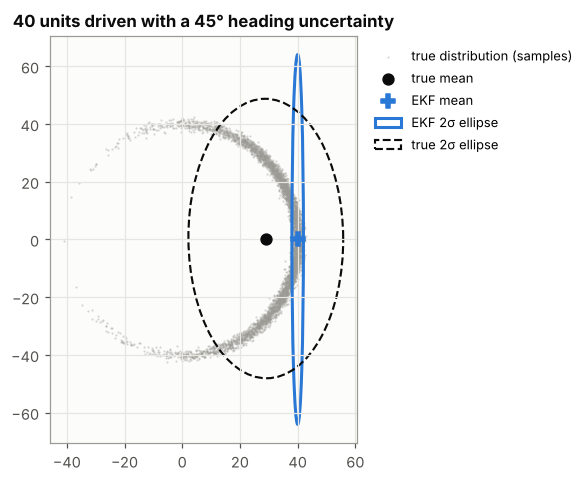

In [6]:
rng = np.random.default_rng(0)
m0, P = np.zeros(3), np.diag([1.0, 1.0, 0.8**2])
samples = rng.multivariate_normal(m0, P, 5000)
m = m0.copy()
u = np.array([4.0, 0.0])
for _ in range(10):
    samples = motion_model(samples, u)
    F, V = motion_jacobians(m, u)
    m, P = motion_model(m, u), F @ P @ F.T

fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.scatter(samples[:, 0], samples[:, 1], s=2, color=viz.MUTED, alpha=0.4, lw=0, label="true distribution (samples)")
mc_mean = samples[:, :2].mean(0)
ax.scatter(*mc_mean, marker="o", s=50, c=viz.INK, label="true mean", zorder=6)
ax.scatter(*m[:2], marker="P", s=80, c=viz.COLORS["EKF"], label="EKF mean", zorder=6)
viz.cov_ellipse(ax, m, P, n_sigma=2, name="EKF", lw=2, label="EKF 2σ ellipse")
viz.cov_ellipse(ax, mc_mean, np.cov(samples[:, :2].T), n_sigma=2, ec=viz.INK, ls="--", label="true 2σ ellipse")
ax.set_aspect("equal"); ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8.5)
ax.set_title("40 units driven with a 45° heading uncertainty")
plt.show()

The true distribution is an arc. The EKF puts its mean at the tip of the arc
($\cos\theta \approx 1$ for $\theta \approx 0$), ahead of the true mean: it ignores that
$\mathbb E[\cos\theta] = e^{-\sigma_\theta^2/2} < 1$. Its ellipse is too thin along the
direction of travel. The linearised model cannot "see" the curvature.

**In the filter.** The same thing happens after an uncertain start. Below, 20 runs start with
an initial estimate drawn from $\mathcal N(x_0, P_0)$ with $\sigma_{xy} = 30$ and
$\sigma_\theta = 0.8$, and the sensor range is limited to 110 units, so that few landmarks are
seen at a time.

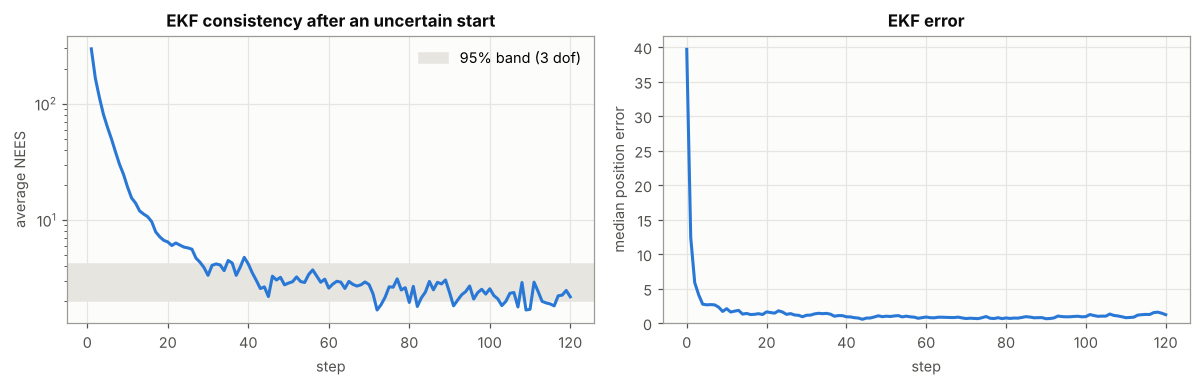

average NEES at steps 1, 5, 20: 297, 63, 6.5   (should be about 3)


In [7]:
world_lr = World.default(max_range=110)
P0 = np.diag([30.0**2, 30.0**2, 0.8**2])
N, T = 20, 120
NE, ER = [], []
for k in range(N):
    r = simulate(world_lr, n_steps=T, seed=k)
    x0 = r.truth[0] + np.random.default_rng(100 + k).multivariate_normal(np.zeros(3), P0)
    rr = run_filter(EKF.from_world(world_lr, x0, P0), r)
    NE.append(nees(rr.means, rr.covs, r.truth)); ER.append(position_error(rr.means, r.truth))
NE, ER = np.array(NE), np.array(ER)
lo, hi = nees_bounds(3, N)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.axhspan(lo, hi, color=viz.GRID, label="95% band (3 dof)")
a1.plot(np.arange(1, T + 1), NE.mean(0)[1:], color=viz.COLORS["EKF"])
a1.set_yscale("log"); a1.set_xlabel("step"); a1.set_ylabel("average NEES"); a1.legend()
a1.set_title("EKF consistency after an uncertain start")
a2.plot(np.median(ER, 0), color=viz.COLORS["EKF"]); a2.set_ylim(bottom=0)
a2.set_xlabel("step"); a2.set_ylabel("median position error"); a2.set_title("EKF error")
plt.tight_layout(); plt.show()
print(f"average NEES at steps 1, 5, 20: {NE[:, 1].mean():.0f}, {NE[:, 5].mean():.0f}, {NE[:, 20].mean():.1f}   (should be about 3)")

The EKF does converge, but during the first ~20 steps its NEES is tens to hundreds of times
too large. It is **over-confident**: its covariance collapsed faster than its error. Each
update was computed with Jacobians evaluated at a wrong estimate, and the linearised model
claimed more information than the measurement really carried. If the error had been larger,
that false confidence could have made the filter reject the very measurements that would have
corrected it.

Common remedies:
* **inflate** $Q$ or $R$ while the filter is uncertain (cheap, ad hoc);
* **iterate** the update, re-linearising at the new estimate (iterated EKF);
* propagate the uncertainty through $f$ and $h$ **without** linearising: the unscented
  transform, next notebook.

A harder limit is that the EKF needs to know **which** landmark each measurement comes from.
Without that (notebook 06), a wrong association produces a confident, wrong update, and the
EKF has no way back.